# MINIEXAMEN 8

### Alumna: Juliette Sinecio Rivera

## 1. Preparación
Todas las secciones parten de este código:

In [5]:
from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# El PDF abre el archivo desde Descargas. Aquí está junto al PDF:
archivo = Path(r"D:\juliette\CLASE PYTHON\Miniexamen8\gfs_data.nc")
# archivo = Path.home() / "Downloads" / "gfs_data.nc"

ds = xr.open_dataset(archivo)

t_2 = ds["t"].sel(lon=100, lev=2)     # temperatura, una columna, nivel 2
t_10 = ds["t"].sel(lon=100, lev=10)   # la misma columna, nivel 10
lat = t_10["geolat"]                  # latitud en grados, igual en todos los niveles

print(t_2.shape, t_10.shape, lat.shape)   # debe salir (240,) (240,) (240,)

(240,) (240,) (240,)


Datos del archivo:
* Los niveles se cuentan de arriba hacia abajo: lev=0 es el tope del modelo.
* t está en K, zh en m, delp en Pa y sphum en kg/kg.
* geolon va de 0 a 360 grados.
* w vale cero en todo el archivo, por lo que no se usa.
* La interfaz del tope (zh en levp=0) da una altura absurda (∼215 km); en las gráficas con altura se deja fuera la capa lev=0

## 2. Anatomía de la figura

a)  Crear la fígura y los ejes con fig, ax = plt.subplots() y gra car t_10 contra lat con ax.plot.

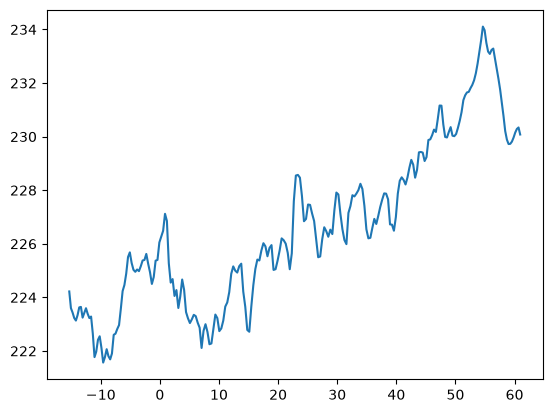

In [6]:
fig, ax = plt.subplots()
ax.plot(lat, t_10)
plt.show()

b)  Agregar ax.set_xlabel, ax.set_ylabel (con unidades) y ax.set_title

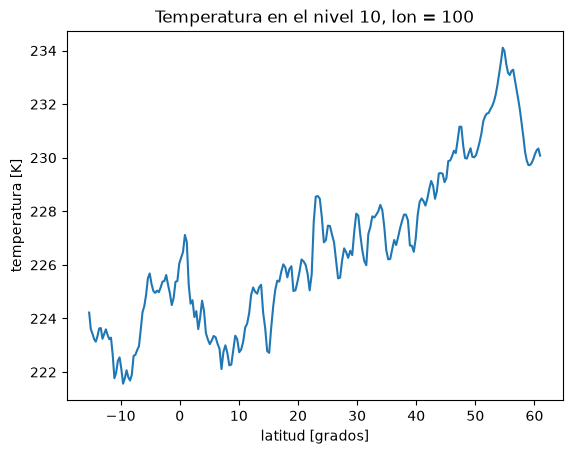

In [7]:
fig, ax = plt.subplots()
ax.plot(lat, t_10)
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("temperatura [K]")
ax.set_title("Temperatura en el nivel 10, lon = 100")
plt.show()

c) Graficar t_2 y t_10 en los mismos ejes, cada una con label=, y mostrar la leyenda con ax.legend().

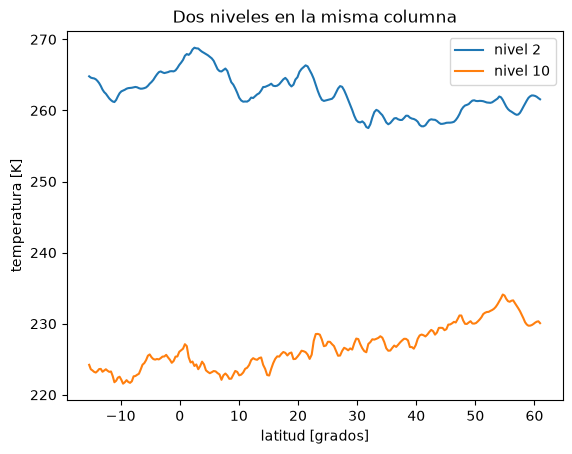

In [8]:
fig, ax = plt.subplots()
ax.plot(lat, t_2, label="nivel 2")
ax.plot(lat, t_10, label="nivel 10")
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("temperatura [K]")
ax.set_title("Dos niveles en la misma columna")
ax.legend()
plt.show()

d)  Mover la leyenda con el argumento loc (ver la tabla de opciones de la leyenda). Probar al menos
tres posiciones.

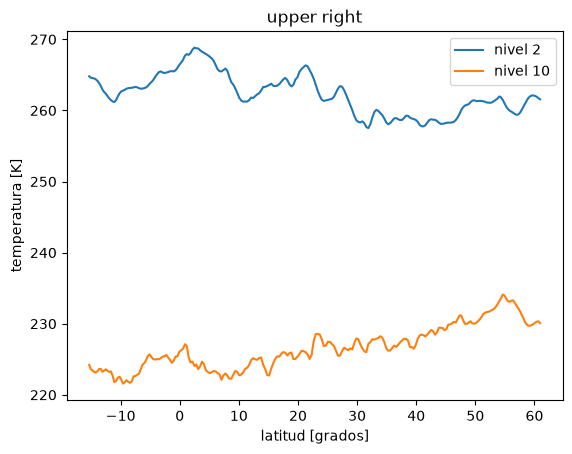

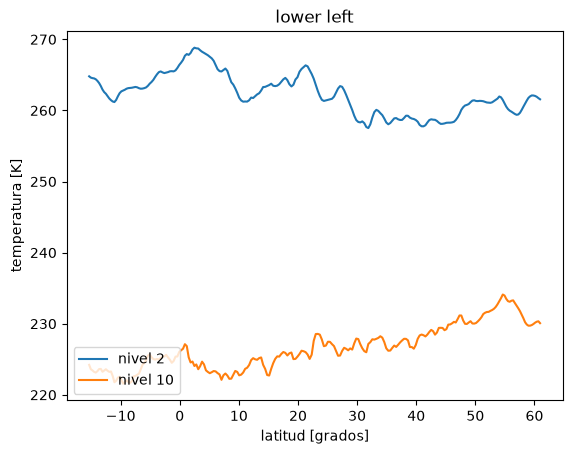

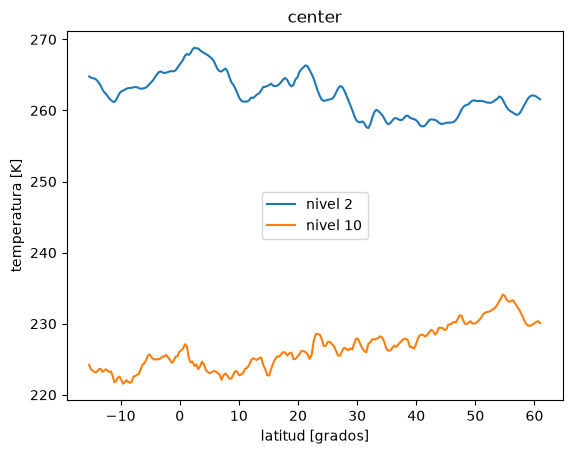

In [9]:
for posicion in ["upper right", "lower left", "center"]:
    fig, ax = plt.subplots()
    ax.plot(lat, t_2, label="nivel 2")
    ax.plot(lat, t_10, label="nivel 10")
    ax.set_xlabel("latitud [grados]")
    ax.set_ylabel("temperatura [K]")
    ax.legend(loc=posicion)
    ax.set_title(posicion)
    plt.show()

e) Sacar la leyenda de la gráfica con bbox_to_anchor y probar las otras opciones de la tabla.

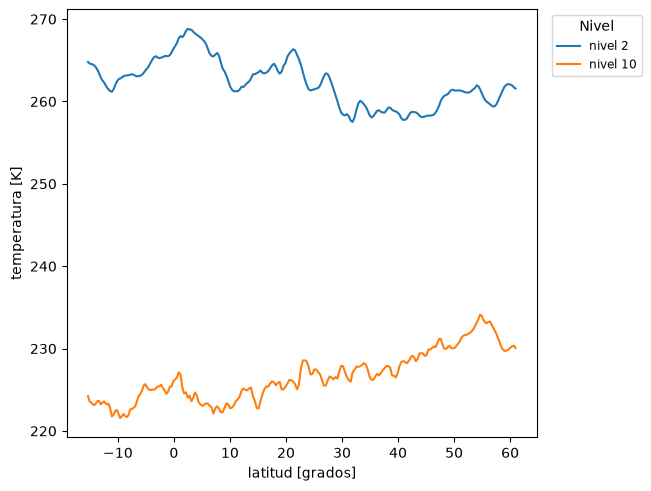

In [10]:
fig, ax = plt.subplots(layout="constrained")
ax.plot(lat, t_2, label="nivel 2")
ax.plot(lat, t_10, label="nivel 10")
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("temperatura [K]")

# (1.02, 1) queda justo afuera, arriba a la derecha.
# loc dice qué esquina de la leyenda se pega a ese punto.
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1),
          ncol=1, title="Nivel", frameon=True, fontsize="small")
plt.show()

f)  Restringir el eje x a latitudes entre 0 y 40 con ax.set_xlim.

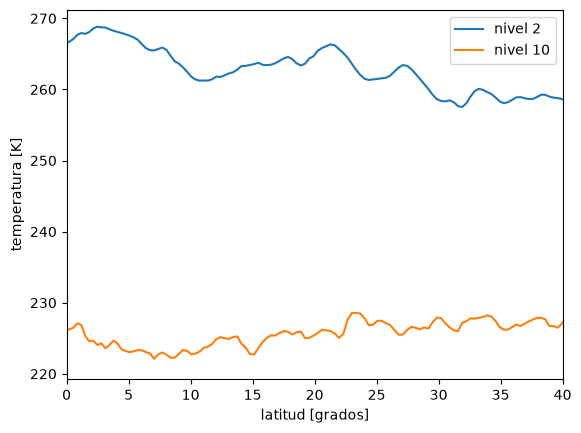

In [11]:
fig, ax = plt.subplots()
ax.plot(lat, t_2, label="nivel 2")
ax.plot(lat, t_10, label="nivel 10")
ax.set_xlim(0, 40)
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("temperatura [K]")
ax.legend()
plt.show()

g) Agregar ax.grid() y probar alpha y linestyle en la rejilla.

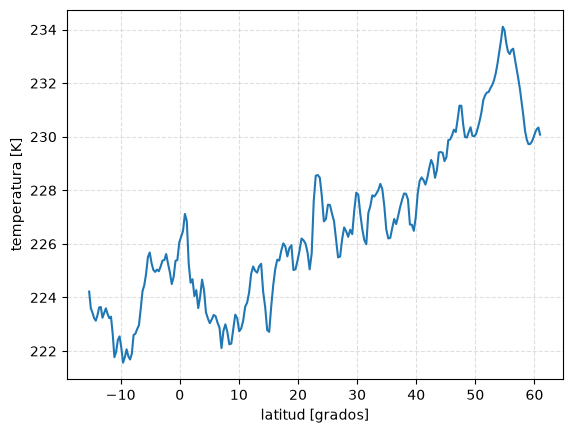

In [12]:
fig, ax = plt.subplots()
ax.plot(lat, t_10)
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("temperatura [K]")
ax.grid(alpha=0.4, linestyle="--")
plt.show()

h)  Cambiar figsize en plt.subplots y guardar la gura con fig.savefig en PNG (dpi=150) y en PDF. Comparar los tamaæos de los archivos y abrirlos con zoom.

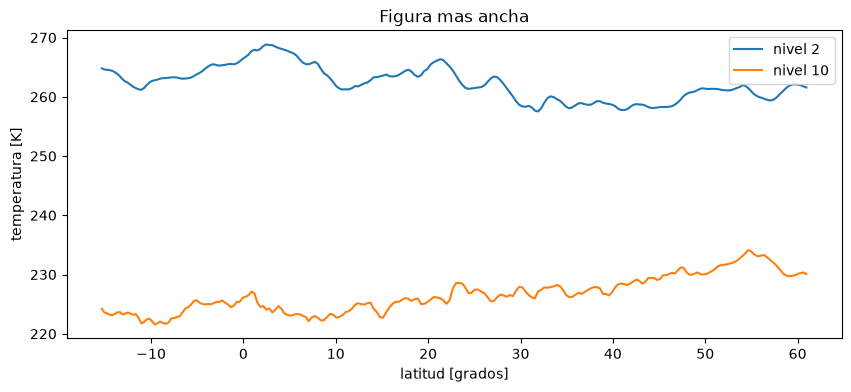

carpeta: C:\Users\juliette\Downloads
PNG: 58697 bytes
PDF: 18142 bytes


In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lat, t_2, label="nivel 2")
ax.plot(lat, t_10, label="nivel 10")
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("temperatura [K]")
ax.set_title("Figura mas ancha")
ax.legend()

fig.savefig("nivel_10.png", dpi=150, bbox_inches="tight")
fig.savefig("nivel_10.pdf", bbox_inches="tight")
plt.show()

png = Path("nivel_10.png")
pdf = Path("nivel_10.pdf")
print("carpeta:", Path.cwd())
print("PNG:", png.stat().st_size, "bytes")
print("PDF:", pdf.stat().st_size, "bytes")

## 3. Estilo de línea y marcadores

a) Graficar t_10 con tres estilos de lnea distintos (’--’, ’:’, ’-.’) y grosores distintos (linewidth)

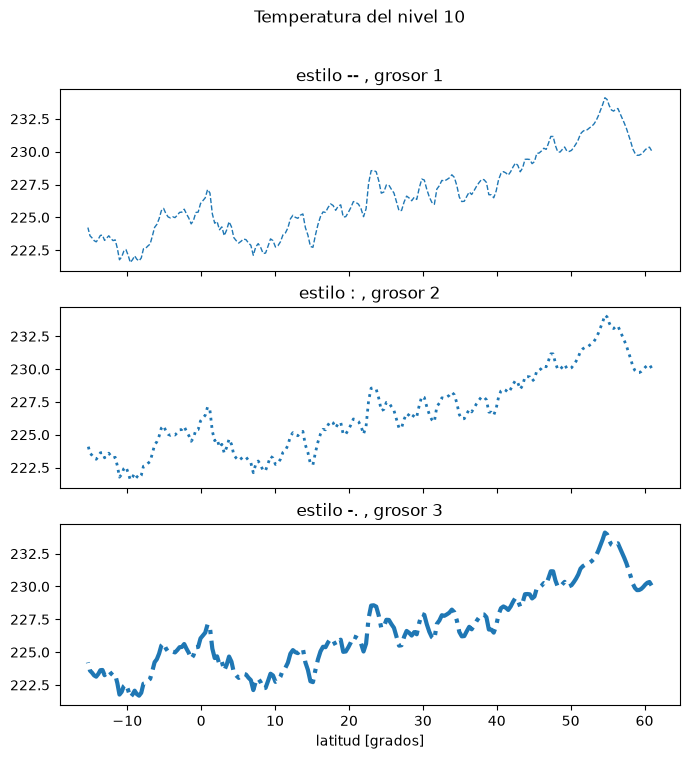

In [14]:
fig, axs = plt.subplots(3, 1, figsize=(8, 8), sharex=True, sharey=True)
axs[0].plot(lat, t_10, linestyle="--", linewidth=1)
axs[0].set_title("estilo -- , grosor 1")
axs[1].plot(lat, t_10, linestyle=":", linewidth=2)
axs[1].set_title("estilo : , grosor 2")
axs[2].plot(lat, t_10, linestyle="-.", linewidth=3)
axs[2].set_title("estilo -. , grosor 3")
axs[2].set_xlabel("latitud [grados]")
fig.suptitle("Temperatura del nivel 10")
plt.show()

b) Agregar marcadores (’o’, ’s’, ’^’) con markersize. Como hay 240 puntos, usar markevery=10 y comparar.

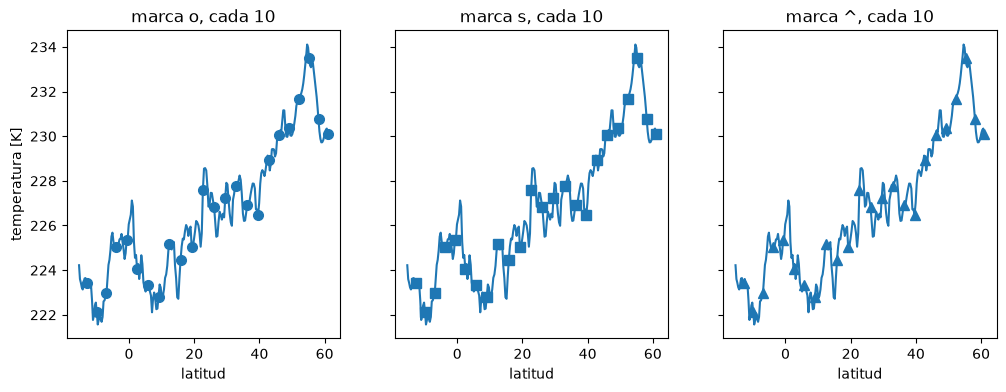

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, marca in zip(axs, ["o", "s", "^"]):
    ax.plot(lat, t_10, linestyle="-", marker=marca, markersize=7, markevery=10)
    ax.set_title("marca " + marca + ", cada 10")
    ax.set_xlabel("latitud")
axs[0].set_ylabel("temperatura [K]")
plt.show()

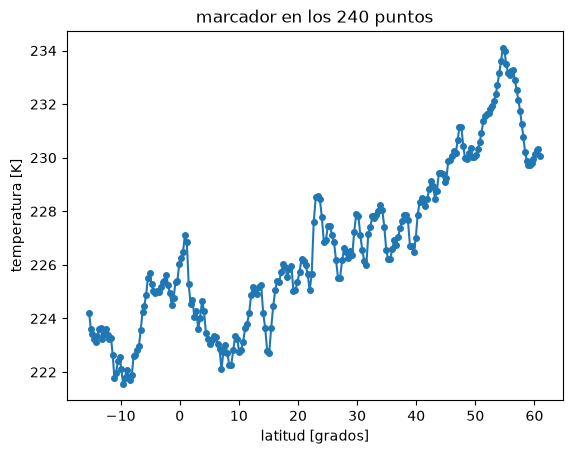

In [16]:
fig, ax = plt.subplots()
ax.plot(lat, t_10, linestyle="-", marker="o", markersize=4)
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("temperatura [K]")
ax.set_title("marcador en los 240 puntos")
plt.show()

c) Separar el color de la lnea del color del marcador con markerfacecolor, markeredgecolor y markeredgewidth. Probar fillstyle=’bottom’ con ’o’.

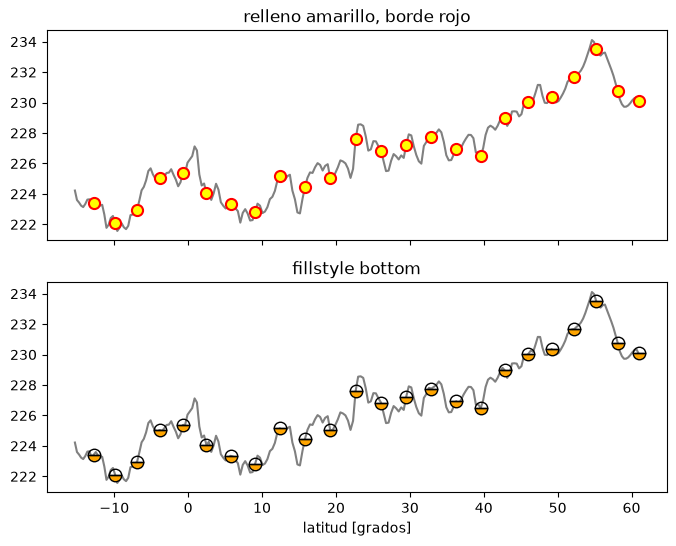

In [17]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.plot(lat, t_10, linestyle="-", color="gray",
         marker="o", markersize=8, markevery=10,
         markerfacecolor="yellow", markeredgecolor="red", markeredgewidth=1.5)
ax1.set_title("relleno amarillo, borde rojo")
ax2.plot(lat, t_10, linestyle="-", color="gray",
         marker="o", markersize=9, markevery=10,
         markerfacecolor="orange", markeredgecolor="black",
         fillstyle="bottom")
ax2.set_title("fillstyle bottom")
ax2.set_xlabel("latitud [grados]")
plt.show()

d)  Usar marcadores de texto, que van entre signos de pesos: r’$\heartsuit$’, r’$\alpha$’, o un carácter Unicode como el sol. La lista de smbolos disponibles se obtiene con:

In [18]:
from matplotlib._mathtext_data import tex2uni
print(sorted(tex2uni))

['#', '$', '%', 'AA', 'AE', 'BbbC', 'BbbN', 'BbbP', 'BbbQ', 'BbbR', 'BbbZ', 'Bumpeq', 'Cap', 'Colon', 'Cup', 'DH', 'Delta', 'Doteq', 'Downarrow', 'Equiv', 'Finv', 'Game', 'Gamma', 'H', 'Im', 'Join', 'L', 'Lambda', 'Ldsh', 'Leftarrow', 'Leftrightarrow', 'Lleftarrow', 'Longleftarrow', 'Longleftrightarrow', 'Longrightarrow', 'Lsh', 'Nearrow', 'Nwarrow', 'O', 'OE', 'Omega', 'P', 'Phi', 'Pi', 'Psi', 'QED', 'Rdsh', 'Re', 'Rightarrow', 'Rrightarrow', 'Rsh', 'S', 'Searrow', 'Sigma', 'Subset', 'Supset', 'Swarrow', 'Theta', 'Thorn', 'Uparrow', 'Updownarrow', 'Upsilon', 'Vdash', 'Vert', 'Vvdash', 'Xi', '_', '__angbracketleft__', '__angbracketright__', '__sqrt__', 'aa', 'ac', 'acute', 'acwopencirclearrow', 'adots', 'ae', 'aleph', 'alpha', 'amalg', 'angle', 'approx', 'approxeq', 'approxident', 'arceq', 'ast', 'asterisk', 'asymp', 'backcong', 'backepsilon', 'backprime', 'backsim', 'backsimeq', 'backslash', 'bagmember', 'bar', 'barleftarrow', 'barvee', 'barwedge', 'because', 'beta', 'beth', 'between'

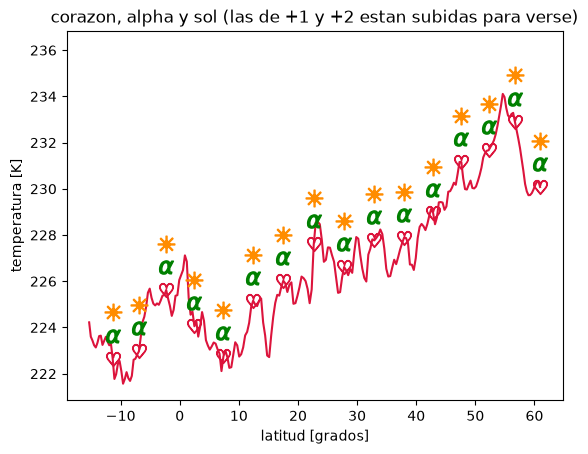

In [20]:
fig, ax = plt.subplots()
ax.plot(lat, t_10, linestyle="-",
        marker=r"$\heartsuit$", markersize=10, markevery=15, color="crimson")
ax.plot(lat, t_10 + 1, linestyle="none",
        marker=r"$\alpha$", markersize=10, markevery=15, color="green")
ax.plot(lat, t_10 + 2, linestyle="none",
        marker="$\u2600$", markersize=12, markevery=15, color="darkorange")
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("temperatura [K]")
ax.set_title("corazon, alpha y sol (las de +1 y +2 estan subidas para verse)")
plt.show()

e) Reproducir una de las grÆ cas anteriores con la forma corta ax.plot(lat, t_10, ’r--o’)

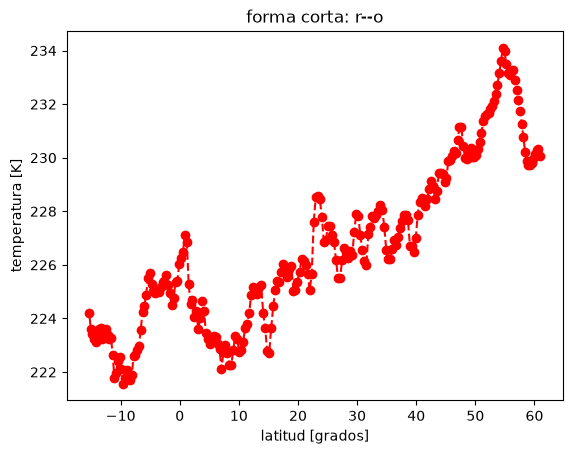

In [21]:
fig, ax = plt.subplots()
ax.plot(lat, t_10, "r--o")
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("temperatura [K]")
ax.set_title("forma corta: r--o")
plt.show()

## 4. Varios ejes en una figura

a) Crear fig, axs = plt.subplots(2, 1) con t_2 arriba y t_10 abajo. Repetirlo desempaquetando: fig, (ax1, ax2) = ....

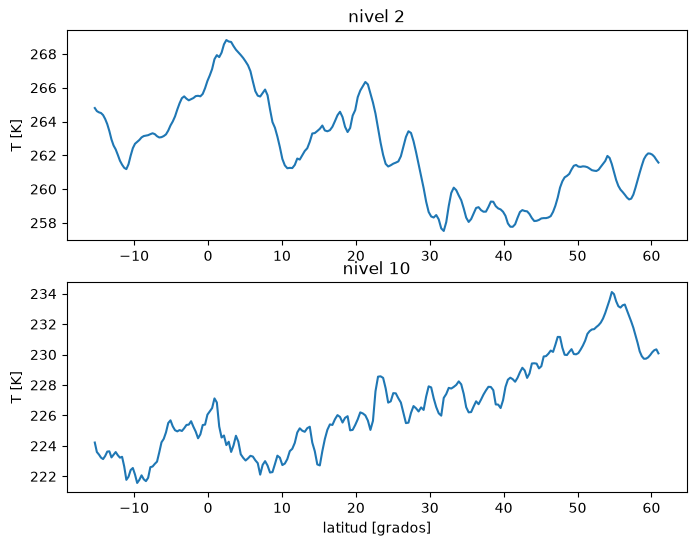

In [22]:
fig, axs = plt.subplots(2, 1, figsize=(8, 6))
axs[0].plot(lat, t_2)
axs[0].set_title("nivel 2")
axs[0].set_ylabel("T [K]")
axs[1].plot(lat, t_10)
axs[1].set_title("nivel 10")
axs[1].set_xlabel("latitud [grados]")
axs[1].set_ylabel("T [K]")
plt.show()

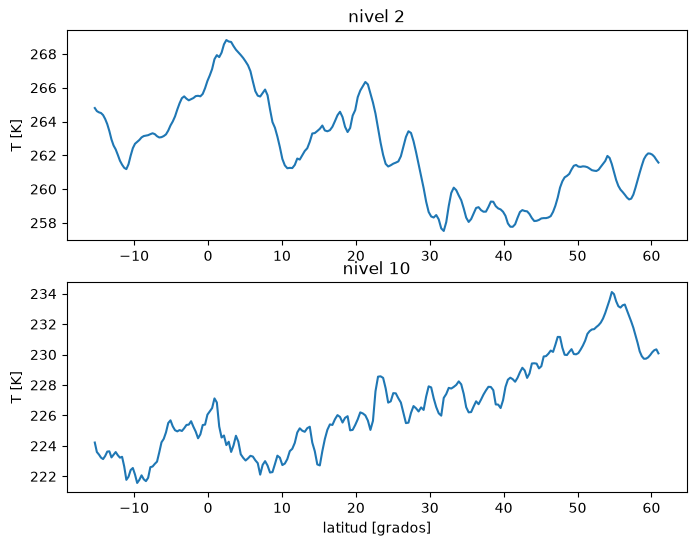

In [23]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6))
ax1.plot(lat, t_2)
ax1.set_title("nivel 2")
ax1.set_ylabel("T [K]")
ax2.plot(lat, t_10)
ax2.set_title("nivel 10")
ax2.set_xlabel("latitud [grados]")
ax2.set_ylabel("T [K]")
plt.show()

b) Agregar sharex=True y luego sharey=True. QuØ cambia y cuÆndo conviene cada uno? Probar layout=’constrained’.

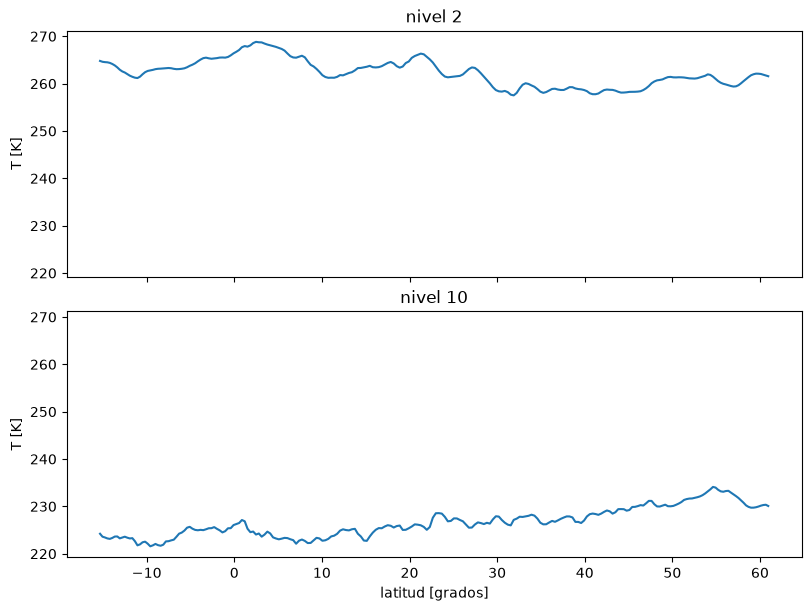

In [24]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6),
                               sharex=True, sharey=True,
                               layout="constrained")
ax1.plot(lat, t_2)
ax1.set_title("nivel 2")
ax1.set_ylabel("T [K]")
ax2.plot(lat, t_10)
ax2.set_title("nivel 10")
ax2.set_xlabel("latitud [grados]")
ax2.set_ylabel("T [K]")
plt.show()

sharex=True obliga a los dos paneles a usar la misma escala de latitud, y las marcas quedan alineadas. Conviene cuando las dos curvas se leen contra la misma latitud. sharey=True obliga a usar la misma escala de temperatura, así que una curva más alta es de verdad más caliente. Conviene al comparar magnitudes; si un nivel está mucho más caliente, el otro se ve aplastado. layout="constrained" separa títulos y nombres de ejes para que no se encimen.

c) Hacer una rejilla de 2×2 con los niveles 2, 10, 20 y 40, llenándola con un ciclo sobre axs.flat.
Poner ttulo a cada panel y uno general con fig.suptitle. Pista: plt.subplots(2, 2) regresa
los ejes en un arreglo de 2×2, as que cada eje se toma con dos ndices (axs[0, 1]). axs.flat
recorre ese arreglo como una sola lista de 4 ejes, y con zip se recorren ejes y niveles al mismo
tiempo: for ax, k in zip(axs.flat, [2, 10, 20, 40]):.

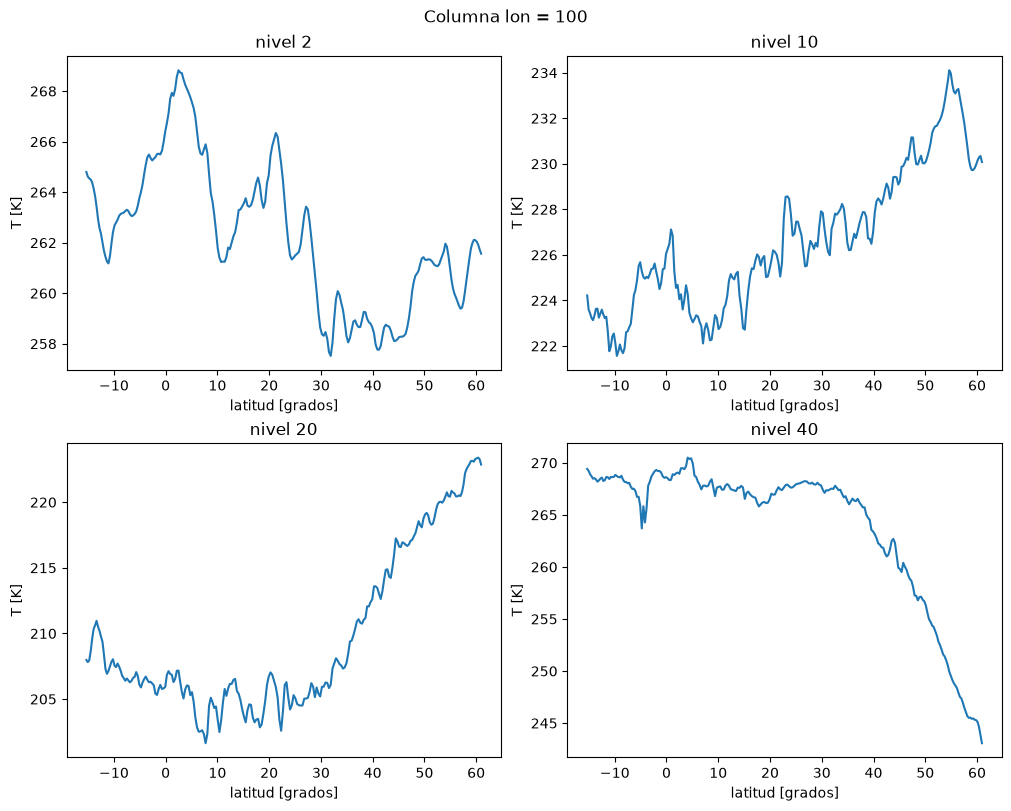

In [25]:
fig, axs = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")
for ax, k in zip(axs.flat, [2, 10, 20, 40]):
    temperatura = ds["t"].sel(lon=100, lev=k)
    ax.plot(temperatura["geolat"], temperatura)
    ax.set_title("nivel " + str(k))
    ax.set_xlabel("latitud [grados]")
    ax.set_ylabel("T [K]")
fig.suptitle("Columna lon = 100")
plt.show()

d) Con GridSpec, armar una gura con un eje grande arriba, que ocupe todo el ancho, y dos ejes
chicos abajo:

Graficar t_10 contra lat en ax1, y t_2 y t_10 por separado en ax2 y ax3. Después, hacer el
eje de arriba el doble de alto que los de abajo con fig.add_gridspec(2, 2, height_ratios=[2,
1]).

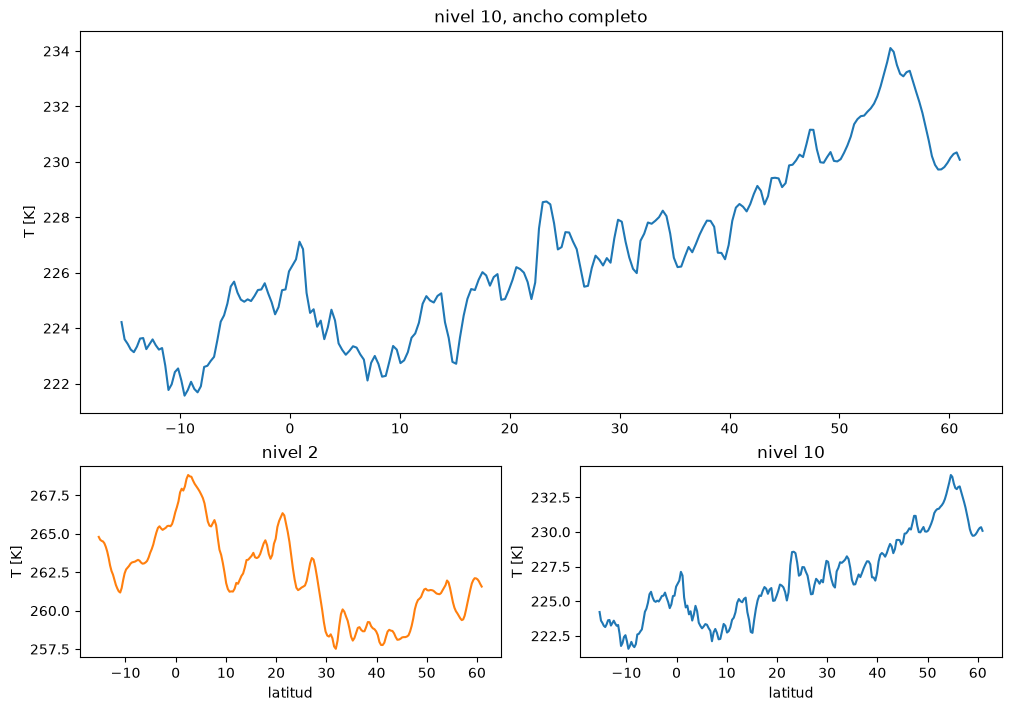

In [26]:
fig = plt.figure(figsize=(10, 7), layout="constrained")
gs = fig.add_gridspec(2, 2, height_ratios=[2, 1])
ax1 = fig.add_subplot(gs[0, :])   # renglon 0, las dos columnas
ax2 = fig.add_subplot(gs[1, 0])   # renglon 1, columna 0
ax3 = fig.add_subplot(gs[1, 1])   # renglon 1, columna 1

ax1.plot(lat, t_10)
ax1.set_title("nivel 10, ancho completo")
ax1.set_ylabel("T [K]")

ax2.plot(lat, t_2, color="C1")
ax2.set_title("nivel 2")
ax2.set_xlabel("latitud")
ax2.set_ylabel("T [K]")

ax3.plot(lat, t_10, color="C0")
ax3.set_title("nivel 10")
ax3.set_xlabel("latitud")
ax3.set_ylabel("T [K]")
plt.show()

e) Con add_axes, colocar cada eje a mano. Cada eje se de ne con [izq, abajo, ancho, alto]:
la posici n de su esquina inferior izquierda y su tamaæo, en fracciones de la gura (0 es el borde
izquierdo o el de abajo y 1 el derecho o el de arriba)

Graficar lo mismo que en el inciso anterior. Después, agregar un cuarto eje chico dentro de ax1,
en una de sus esquinas. ¿Se podra hacer eso con subplots o con GridSpec?

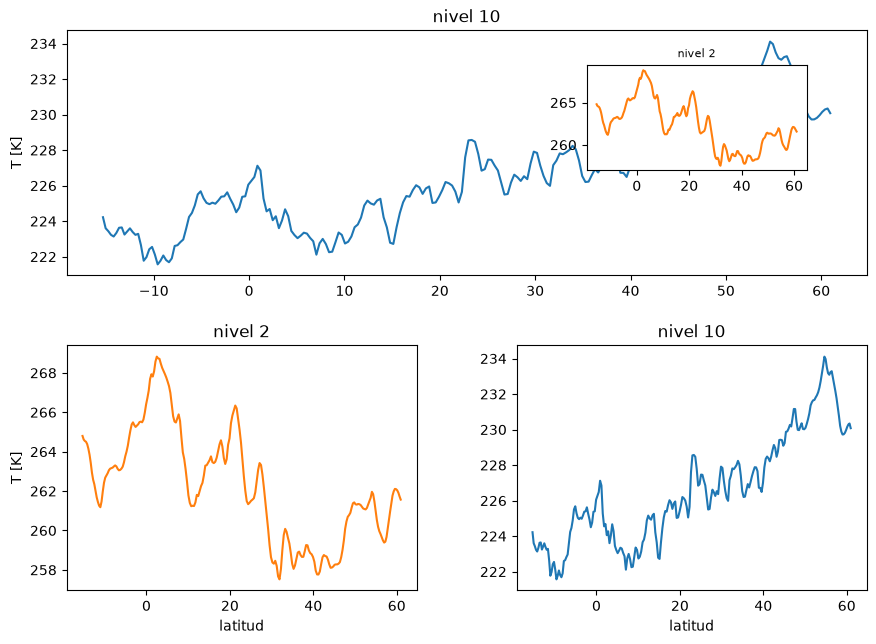

In [27]:
fig = plt.figure(figsize=(10, 7))
ax1 = fig.add_axes([0.10, 0.55, 0.80, 0.35])
ax2 = fig.add_axes([0.10, 0.10, 0.35, 0.35])
ax3 = fig.add_axes([0.55, 0.10, 0.35, 0.35])

ax1.plot(lat, t_10)
ax1.set_title("nivel 10")
ax1.set_ylabel("T [K]")

ax2.plot(lat, t_2, color="C1")
ax2.set_title("nivel 2")
ax2.set_xlabel("latitud")
ax2.set_ylabel("T [K]")

ax3.plot(lat, t_10, color="C0")
ax3.set_title("nivel 10")
ax3.set_xlabel("latitud")

# eje chico dentro de ax1, en la esquina superior derecha
ax4 = fig.add_axes([0.62, 0.70, 0.22, 0.15])
ax4.plot(lat, t_2, color="C1")
ax4.set_title("nivel 2", fontsize=8)
plt.show()

 ese eje de adentro se coloca con add_axes, porque la posición la escribes tú a manita. subplots arma una rejilla de ejes separados. GridSpec también reparte la figura en celdas, como el panel ancho de arriba; no mete un eje dentro de otro.

f) Con ax2 = ax1.twinx(), gra car t_2 y t_10 cada una con su propio eje y. Colorear cada eje
igual que su lnea con tick_params(axis=’y’, colors=...).

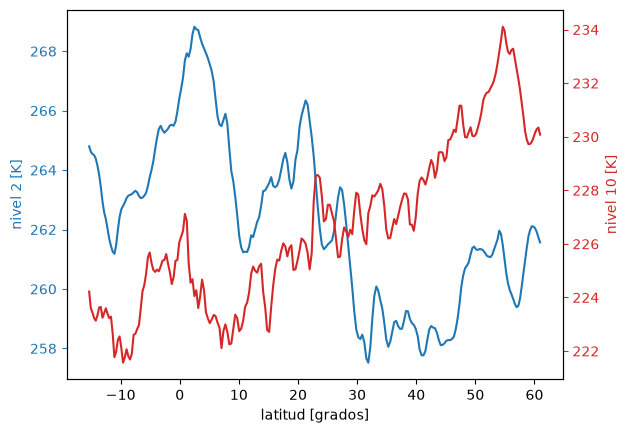

In [28]:
fig, ax1 = plt.subplots()
ax1.plot(lat, t_2, color="tab:blue")
ax1.set_xlabel("latitud [grados]")
ax1.set_ylabel("nivel 2 [K]", color="tab:blue")
ax1.tick_params(axis="y", colors="tab:blue")

ax2 = ax1.twinx()
ax2.plot(lat, t_10, color="tab:red")
ax2.set_ylabel("nivel 10 [K]", color="tab:red")
ax2.tick_params(axis="y", colors="tab:red")
plt.show()

g) Agregar un eje derecho en ◦C con secondary_yaxis. Necesita la conversión de ida y la de regreso. Después, poner mal la función de regreso a propósito y explicar qué pasa.

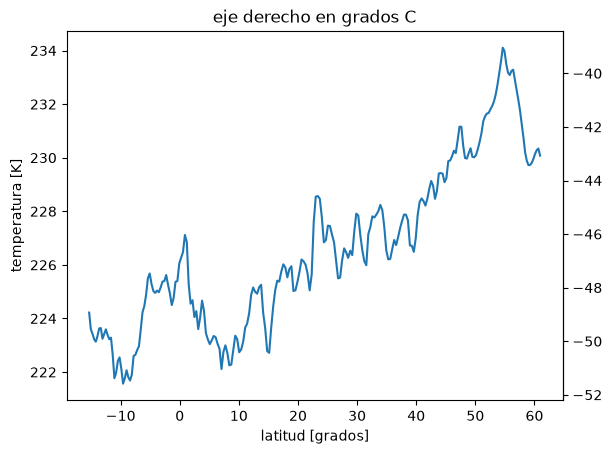

In [29]:
fig, ax = plt.subplots()
ax.plot(lat, t_10, color="tab:blue")
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("temperatura [K]")
ax.secondary_yaxis("right", functions=(lambda k: k - 273.15,
                                       lambda c: c + 273.15))
ax.set_title("eje derecho en grados C")
plt.show()

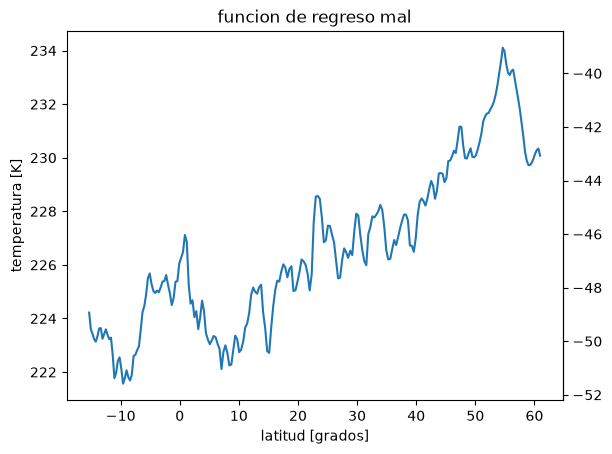

In [30]:
fig, ax = plt.subplots()
ax.plot(lat, t_10, color="tab:blue")
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("temperatura [K]")
ax.secondary_yaxis("right", functions=(lambda k: k - 273.15,
                                       lambda c: c - 273.15))
ax.set_title("funcion de regreso mal")
plt.show()

matplotlib usa la segunda función para decidir dónde poner cada número del eje derecho. Si esa función también resta 273.15, los °C dejan de ser la misma temperatura que la curva: las marcas caen fuera de la gráfica o junto a un valor que no es el de la línea.

h) ¿En qué se diferencian twinx y secondary_yaxis? Responder con una frase para cada uno.

twinx crea un segundo eje y independiente, para otra curva con su propia escala. secondary_yaxis muestra la misma curva en otras unidades, con una fórmula que convierte de ida y de vuelta.

## Ejes invertidos y logarítmicos

In [33]:
col = dict(lat=100, lon=100)
t_col = ds["t"].sel(**col).values[1:]

zh = ds["zh"].sel(**col).values
z_km = 0.5 * (zh[:-1] + zh[1:])[1:] / 1000   # altura a media capa, en km

delp = ds["delp"].sel(**col)
p_hpa = (delp.cumsum("lev") - delp / 2).values[1:] / 100   # presion a media capa, en hPa

print(t_col.shape, z_km.shape, p_hpa.shape)

(64,) (64,) (64,)


a) Graficar la temperatura en x y la altura en y. ¿Por qué en los perfiles verticales se pone la variable en x?

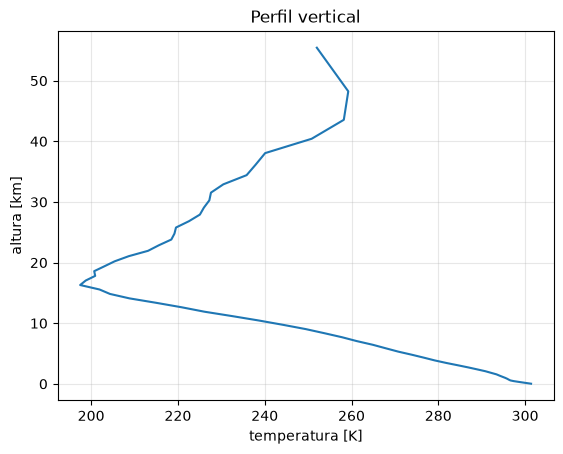

In [34]:
fig, ax = plt.subplots()
ax.plot(t_col, z_km)
ax.set_xlabel("temperatura [K]")
ax.set_ylabel("altura [km]")
ax.set_title("Perfil vertical")
ax.grid(alpha=0.3)
plt.show()

En un perfil vertical la altura es la coordenada de arriba hacia abajo, así que va en y, como en un corte de la atmósfera. La temperatura es la cantidad que cambia con la altura, y se lee en x.

b) Cambiar la altura por la presión. La gráfica queda de cabeza; corregirla con ax.invert_yaxis().

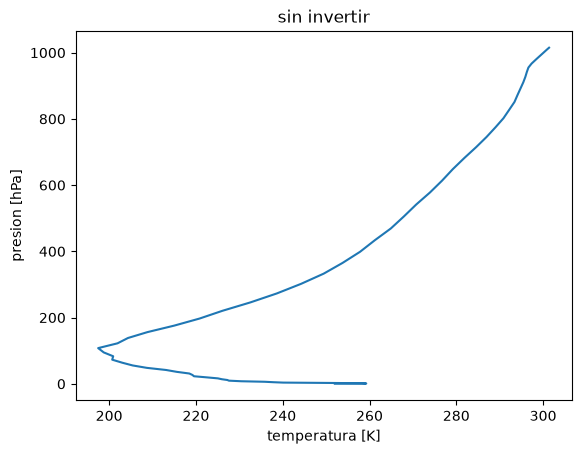

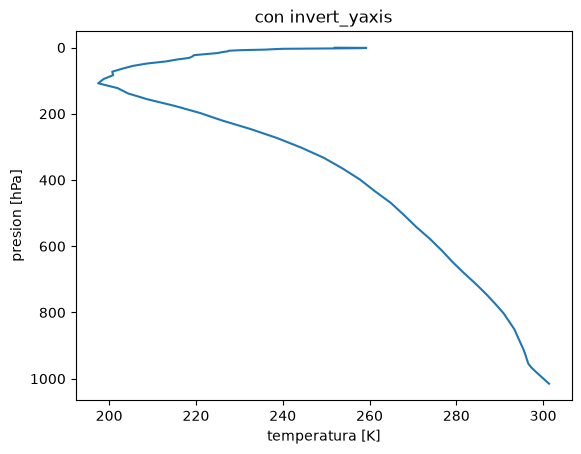

In [35]:
fig, ax = plt.subplots()
ax.plot(t_col, p_hpa)
ax.set_xlabel("temperatura [K]")
ax.set_ylabel("presion [hPa]")
ax.set_title("sin invertir")
plt.show()

fig, ax = plt.subplots()
ax.plot(t_col, p_hpa)
ax.invert_yaxis()
ax.set_xlabel("temperatura [K]")
ax.set_ylabel("presion [hPa]")
ax.set_title("con invert_yaxis")
plt.show()

c) Poner el eje de presión en escala logartmica y jar marcas en 1000, 500, 200, 100, 50, 10 y 1 hPa con ax.set_yticks(valores, etiquetas). Pista: etiquetas es una lista de textos, por ejemplo [’1000’, ’500’, ...]

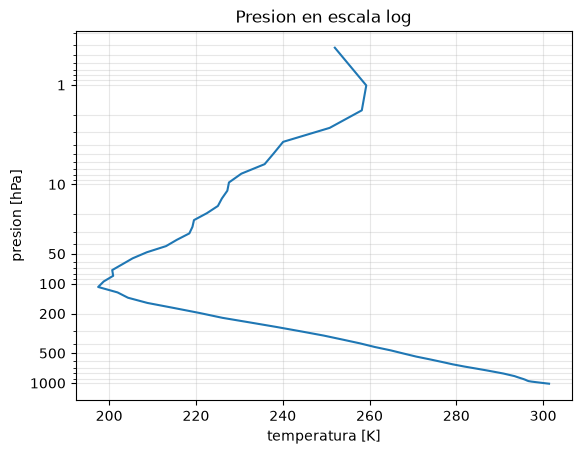

In [36]:
fig, ax = plt.subplots()
ax.plot(t_col, p_hpa)
ax.invert_yaxis()
ax.set_yscale("log")

valores = [1000, 500, 200, 100, 50, 10, 1]
etiquetas = ["1000", "500", "200", "100", "50", "10", "1"]
ax.set_yticks(valores, etiquetas)

ax.set_xlabel("temperatura [K]")
ax.set_ylabel("presion [hPa]")
ax.set_title("Presion en escala log")
ax.grid(alpha=0.3, which="both")
plt.show()

d) Marcar un nivel con ax.axhline, con una etiqueta en la leyenda.

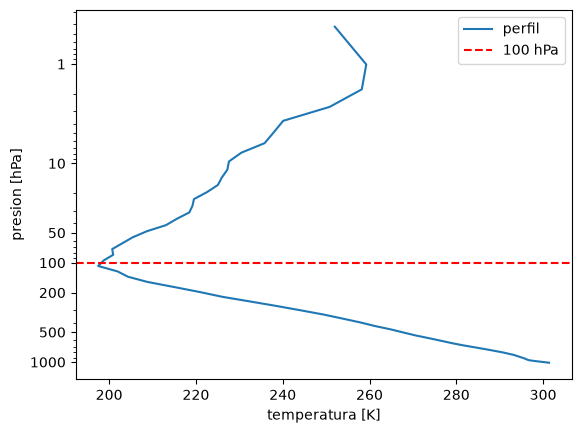

In [37]:
fig, ax = plt.subplots()
ax.plot(t_col, p_hpa, label="perfil")
ax.axhline(100, color="red", linestyle="--", label="100 hPa")
ax.invert_yaxis()
ax.set_yscale("log")
ax.set_yticks(valores, etiquetas)
ax.set_xlabel("temperatura [K]")
ax.set_ylabel("presion [hPa]")
ax.legend()
plt.show()

e) Superponer en los mismos ejes los perfiles de 5 columnas distintas con un ciclo y alpha. Pista: dentro del ciclo se repite el código de arriba con otro col, por ejemplo recorriendo una lista de pares: for la, lo in [(20, 50), (100, 100), ...]: y luego col = dict(lat=la, lon=lo).

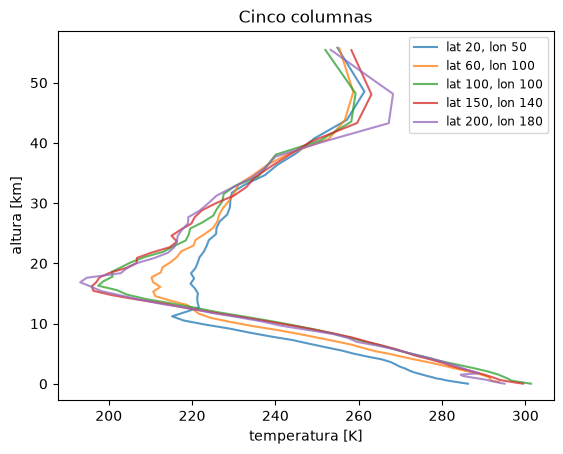

In [38]:
fig, ax = plt.subplots()
pares = [(20, 50), (60, 100), (100, 100), (150, 140), (200, 180)]

for la, lo in pares:
    col = dict(lat=la, lon=lo)
    t_col = ds["t"].sel(**col).values[1:]
    zh = ds["zh"].sel(**col).values
    z_km = 0.5 * (zh[:-1] + zh[1:])[1:] / 1000
    ax.plot(t_col, z_km, alpha=0.75, label="lat " + str(la) + ", lon " + str(lo))

ax.set_xlabel("temperatura [K]")
ax.set_ylabel("altura [km]")
ax.set_title("Cinco columnas")
ax.legend(fontsize="small")
plt.show()

## 6. Bandas sombreadas

a) Graficar t_2 y t_10 contra lat y sombrear el espacio entre ellas con ax.fill_between(lat, t_2, t_10, alpha=0.3).

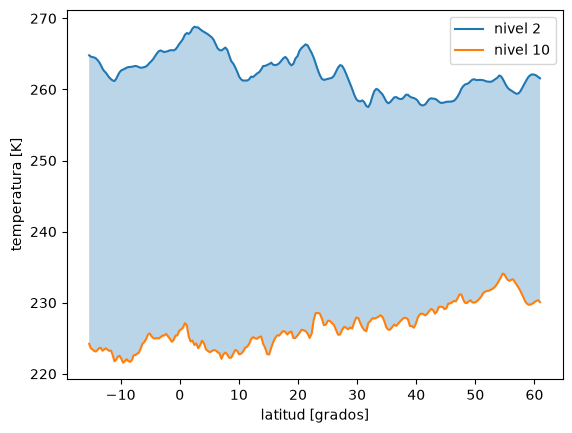

In [39]:
fig, ax = plt.subplots()
ax.plot(lat, t_2, label="nivel 2")
ax.plot(lat, t_10, label="nivel 10")
ax.fill_between(lat, t_2, t_10, alpha=0.3)
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("temperatura [K]")
ax.legend()
plt.show()

b) Calcular la anomalía anom = t_10- t_10.mean() y sombrear de un color donde anom > 0 y de otro donde anom < 0, con where= y contra el cero. Hacerlo primero sin y luego con interpolate=True, y comparar qué pasa en los cruces por cero. Pista: cada llamada a fill_between usa un solo color, así que se llama dos veces, una con cada condición en where=.

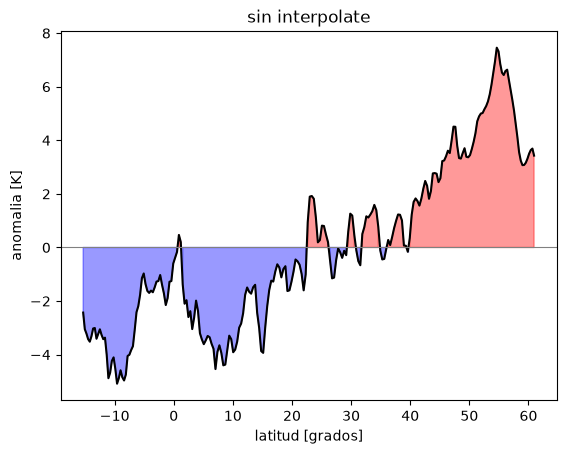

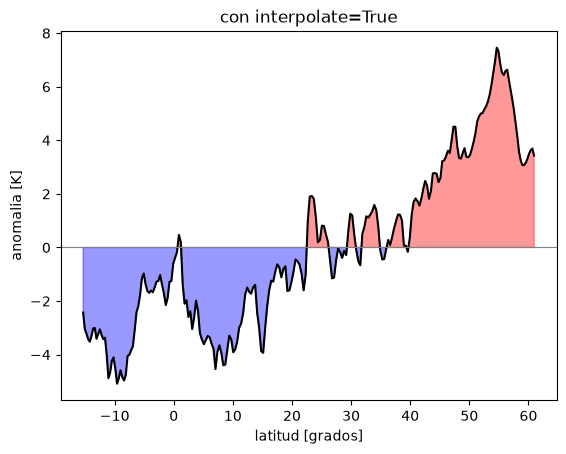

In [40]:
anom = t_10.values - t_10.values.mean()

fig, ax = plt.subplots()
ax.plot(lat, anom, color="black")
ax.axhline(0, color="gray", linewidth=0.8)
ax.fill_between(lat.values, 0, anom, where=anom > 0, color="red", alpha=0.4)
ax.fill_between(lat.values, 0, anom, where=anom < 0, color="blue", alpha=0.4)
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("anomalia [K]")
ax.set_title("sin interpolate")
plt.show()

fig, ax = plt.subplots()
ax.plot(lat, anom, color="black")
ax.axhline(0, color="gray", linewidth=0.8)
ax.fill_between(lat.values, 0, anom, where=anom > 0, color="red", alpha=0.4, interpolate=True)
ax.fill_between(lat.values, 0, anom, where=anom < 0, color="blue", alpha=0.4, interpolate=True)
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("anomalia [K]")
ax.set_title("con interpolate=True")
plt.show()

Cada fill_between pinta un solo color. Sin interpolate, el color se corta en el último punto de la malla que todavía cumple la condición, y en el cruce por cero queda un hueco. Con interpolate=True, matplotlib calcula el punto exacto donde la anomalía vale cero y ahí se encuentran los dos colores.

c) Calcular para cada nivel el promedio, el mnimo y el mÆximo de t en todo el dominio (.mean([’lat’, ’lon’]), etc.). Gra car el promedio como per l vertical (como en la sección 5) y la banda mínimo-máximo con ax.fill_betweenx. Pista: en fill_betweenx(y, x1, x2) el primer argumento es la coordenada vertical (aqu, ds[’t’].lev) y los otros dos son los bordes de la banda. Como lev=0 es el tope, hay que invertir el eje y.

d) Hacer que la banda aparezca en la leyenda con label=.

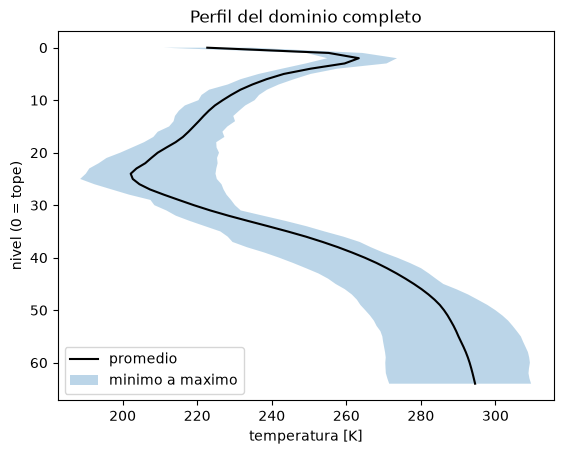

In [41]:
promedio = ds["t"].mean(["lat", "lon"])
minimo = ds["t"].min(["lat", "lon"])
maximo = ds["t"].max(["lat", "lon"])
nivel = promedio.lev

fig, ax = plt.subplots()
ax.plot(promedio, nivel, color="black", label="promedio")
ax.fill_betweenx(nivel, minimo, maximo, alpha=0.3, label="minimo a maximo")
ax.invert_yaxis()
ax.set_xlabel("temperatura [K]")
ax.set_ylabel("nivel (0 = tope)")
ax.set_title("Perfil del dominio completo")
ax.legend()
plt.show()

## 7. Distribuciones: histogramas, scatter, hist2d, hexbin

Los incisos a), b) y f) usan lev=10 (∼30 km). Los incisos c) a e) usan lev=50 (∼2 km), porque arriba casi no hay vapor de agua y el scatter con humedad no mostrara nada. En todos se usan todos los puntos del nivel, aplanados con .values.ravel().

a) Hacer el histograma de t en lev=10 con ax.hist. Probar bins= (10, 50, 200) y density=True. ¿Qué forma tiene y por qué no es una campana?

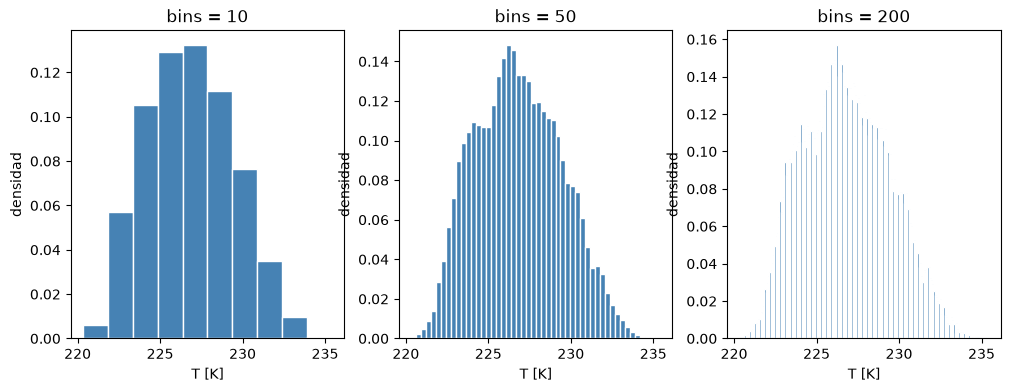

In [42]:
t10 = ds["t"].sel(lev=10).values.ravel()

fig, axs = plt.subplots(1, 3, figsize=(12, 4), sharey=False)
for ax, n in zip(axs, [10, 50, 200]):
    ax.hist(t10, bins=n, density=True, color="steelblue", edgecolor="white")
    ax.set_title("bins = " + str(n))
    ax.set_xlabel("T [K]")
    ax.set_ylabel("densidad")
plt.show()

Sale una joroba ancha entre unos 220 K y 235 K, no un pico delgado. No es una campana porque estos valores no son números al azar de una sola temperatura: son la temperatura en cada punto del mapa. Los puntos vecinos se parecen, y la temperatura cambia sobre todo con la latitud. El histograma cuenta cuánta área hay en cada temperatura. Con 10 barras se ve el bulto; con 50, el detalle; con 200, las barras saltan porque cada una tiene pocos puntos.

b) Superponer el histograma de otro nivel, con los mismos bordes de los bins para los dos (np.linspace). Usar histtype=’step’ o alpha para que se vean ambos, y label= con leyenda. Pista: bins = np.linspace(vmin, vmax, 51) da 50 bins entre vmin y vmax; se usan el mínimo y el máximo de los dos niveles juntos, y se pasa bins=bins a las dos llamadas.

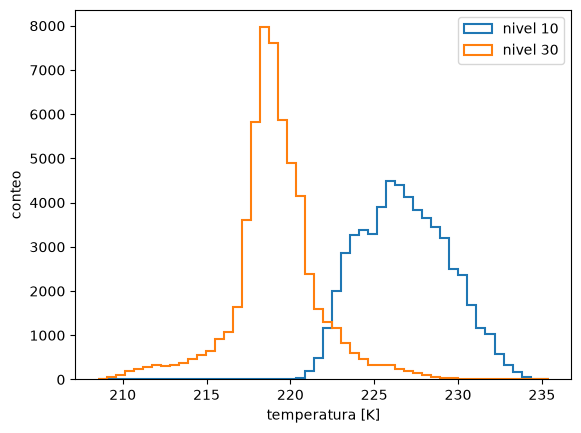

In [43]:
t10 = ds["t"].sel(lev=10).values.ravel()
t30 = ds["t"].sel(lev=30).values.ravel()
vmin = min(t10.min(), t30.min())
vmax = max(t10.max(), t30.max())
bins = np.linspace(vmin, vmax, 51)

fig, ax = plt.subplots()
ax.hist(t10, bins=bins, histtype="step", linewidth=1.5, label="nivel 10")
ax.hist(t30, bins=bins, histtype="step", linewidth=1.5, label="nivel 30")
ax.set_xlabel("temperatura [K]")
ax.set_ylabel("conteo")
ax.legend()
plt.show()

c) Hacer un scatter de t contra sphum en lev=50. Variar s= y alpha=. ¿Qué problema tiene?

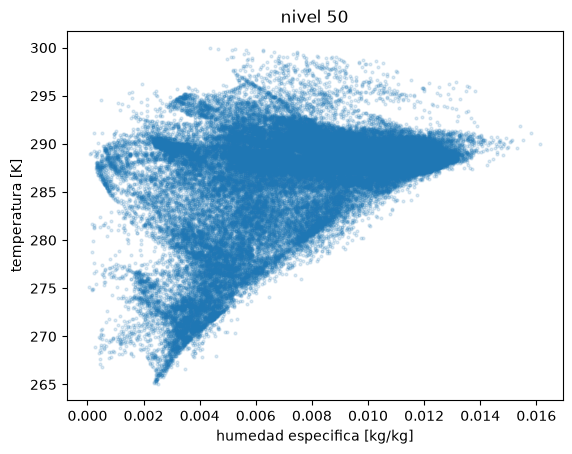

In [44]:
temp = ds["t"].sel(lev=50).values.ravel()
humedad = ds["sphum"].sel(lev=50).values.ravel()

fig, ax = plt.subplots()
ax.scatter(humedad, temp, s=4, alpha=0.15)
ax.set_xlabel("humedad especifica [kg/kg]")
ax.set_ylabel("temperatura [K]")
ax.set_title("nivel 50")
plt.show()

Son 240 × 240 = 57600 puntos, y muchos caen uno encima de otro. Bajar s o alpha aclara la mancha, y aun así no se ve cuántos puntos hay en cada zona.

d) Colorear los puntos por latitud (c=geolat, cmap=) y agregar fig.colorbar. Pista: la latitud también se aplana: c=ds[’geolat’].values.ravel(). La barra de color necesita lo que regresa scatter: sc = ax.scatter(...) y luego fig.colorbar(sc, ax=ax).

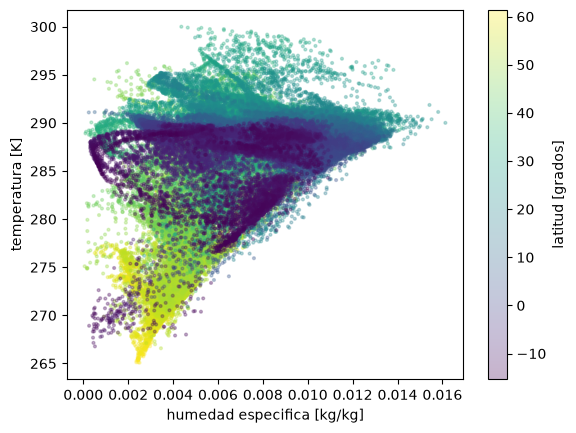

In [45]:
temp = ds["t"].sel(lev=50).values.ravel()
humedad = ds["sphum"].sel(lev=50).values.ravel()
latitud = ds["geolat"].values.ravel()

fig, ax = plt.subplots()
sc = ax.scatter(humedad, temp, c=latitud, s=4, alpha=0.3, cmap="viridis")
fig.colorbar(sc, ax=ax, label="latitud [grados]")
ax.set_xlabel("humedad especifica [kg/kg]")
ax.set_ylabel("temperatura [K]")
plt.show()

e) Repetirlo con ax.hist2d y luego con ax.hexbin. Probar bins y gridsize, quitar las celdas vacías (cmin=1 / mincnt=1) y usar escala logarítmica (norm=LogNorm() / bins=’log’). Agregar barra de color a los dos. Pista: LogNorm se importa con from matplotlib.colors import LogNorm. hist2d regresa cuatro cosas y la barra de color necesita la œltima: h = ax.hist2d(...) y fig.colorbar(h[3], ax=ax). hexbin regresa directamente lo que necesita la barra.

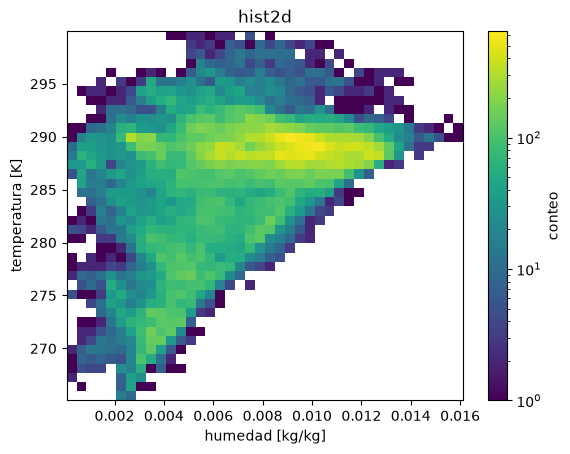

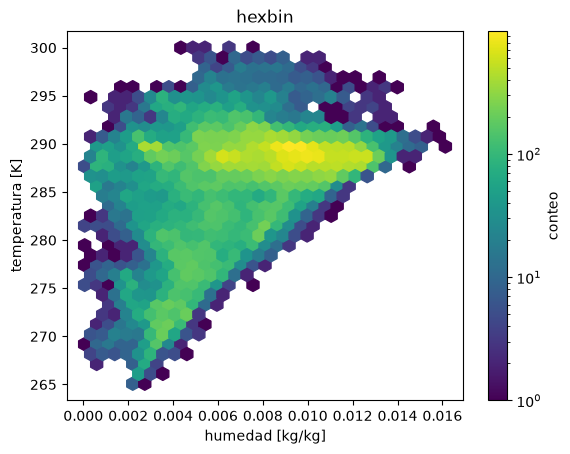

In [46]:
from matplotlib.colors import LogNorm

temp = ds["t"].sel(lev=50).values.ravel()
humedad = ds["sphum"].sel(lev=50).values.ravel()

fig, ax = plt.subplots()
h = ax.hist2d(humedad, temp, bins=40, cmin=1, norm=LogNorm())
fig.colorbar(h[3], ax=ax, label="conteo")
ax.set_xlabel("humedad [kg/kg]")
ax.set_ylabel("temperatura [K]")
ax.set_title("hist2d")
plt.show()

fig, ax = plt.subplots()
hb = ax.hexbin(humedad, temp, gridsize=30, mincnt=1, bins="log", cmap="viridis")
fig.colorbar(hb, ax=ax, label="conteo")
ax.set_xlabel("humedad [kg/kg]")
ax.set_ylabel("temperatura [K]")
ax.set_title("hexbin")
plt.show()

f) Hacer el histograma acumulado de t en lev=10 con cumulative=True y histtype=’step’. Marcar la mediana con ax.axhline(0.5).

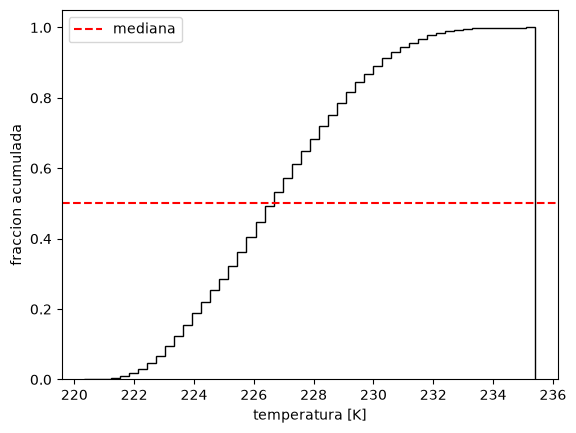

In [47]:
t10 = ds["t"].sel(lev=10).values.ravel()

fig, ax = plt.subplots()
ax.hist(t10, bins=50, cumulative=True, density=True, histtype="step", color="black")
ax.axhline(0.5, color="red", linestyle="--", label="mediana")
ax.set_xlabel("temperatura [K]")
ax.set_ylabel("fraccion acumulada")
ax.legend()
plt.show()

g) Hacer el scatter de o3mr contra t en lev=10, coloreado por latitud. ¿La relación es de causa y efecto?

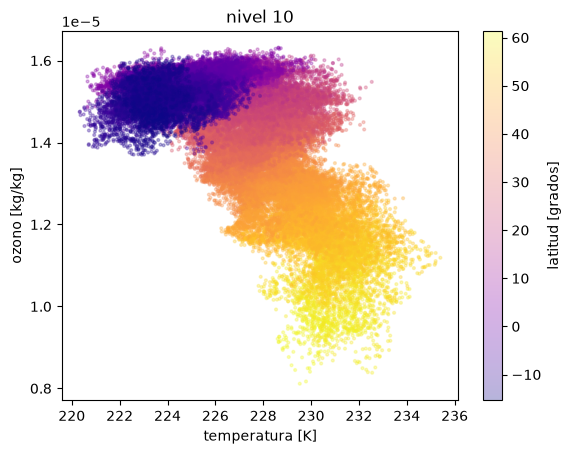

In [48]:
temp = ds["t"].sel(lev=10).values.ravel()
ozono = ds["o3mr"].sel(lev=10).values.ravel()
latitud = ds["geolat"].values.ravel()

fig, ax = plt.subplots()
sc = ax.scatter(temp, ozono, c=latitud, s=4, alpha=0.3, cmap="plasma")
fig.colorbar(sc, ax=ax, label="latitud [grados]")
ax.set_xlabel("temperatura [K]")
ax.set_ylabel("ozono [kg/kg]")
ax.set_title("nivel 10")
plt.show()

Se ve que el ozono y la temperatura cambian juntos, y el color muestra que los dos cambian con la latitud. Eso es una relación entre las dos variables. Esta figura no demuestra que una cause a la otra.

## 8. Campos 2D

a) Graficar t en lev=10 con ax.pcolormesh(ds.geolon, ds.geolat, campo) y agregar fig.colorbar(..., label=’K’). Comparar con campo.plot(x=’geolon’, y=’geolat’) de xarray. Pista: campo = ds[’t’].sel(lev=10). La barra de color necesita lo que regresa pcolormesh:mesh = ax.pcolormesh(...) y fig.colorbar(mesh, ax=ax, label=’K’).

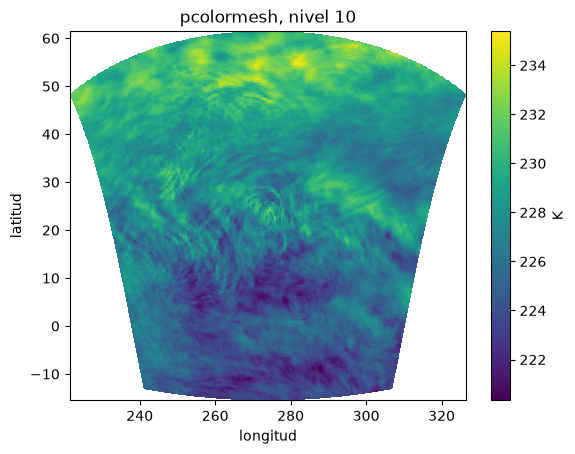

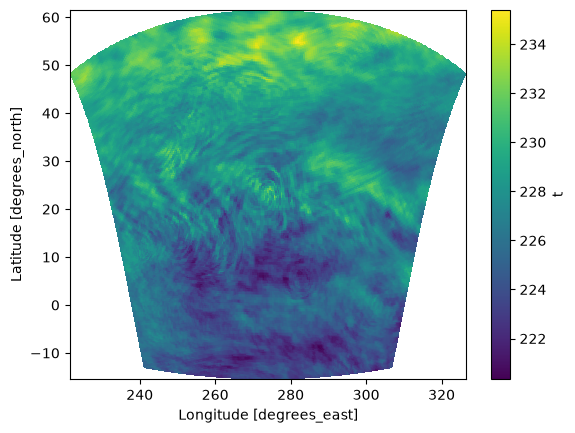

In [49]:
campo = ds["t"].sel(lev=10)

fig, ax = plt.subplots()
mesh = ax.pcolormesh(ds.geolon, ds.geolat, campo)
fig.colorbar(mesh, ax=ax, label="K")
ax.set_xlabel("longitud")
ax.set_ylabel("latitud")
ax.set_title("pcolormesh, nivel 10")
plt.show()

campo.plot(x="geolon", y="geolat")
plt.show()

b) Hacer lo mismo con contourf, jando levels=. Encima, dibujar contour en negro con etiquetas ax.clabel. Pista: clabel recibe lo que regresa contour: cs = ax.contour(...) y ax.clabel(cs).

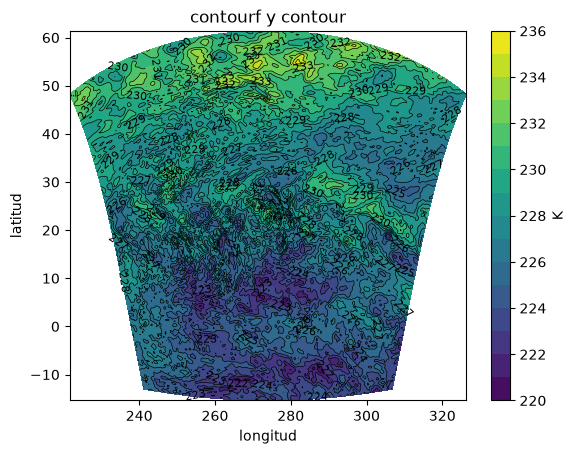

In [50]:
campo = ds["t"].sel(lev=10)

fig, ax = plt.subplots()
cf = ax.contourf(ds.geolon, ds.geolat, campo, levels=15, cmap="viridis")
cs = ax.contour(ds.geolon, ds.geolat, campo, levels=cf.levels,
                colors="black", linewidths=0.5)
ax.clabel(cs, fontsize=8)
fig.colorbar(cf, ax=ax, label="K")
ax.set_xlabel("longitud")
ax.set_ylabel("latitud")
ax.set_title("contourf y contour")
plt.show()

c) Probar cuatro colormaps (viridis, plasma, coolwarm, RdBu_r) y la versi n invertida con _r. ¿Cuál conviene para temperatura y cuál para una anomala?

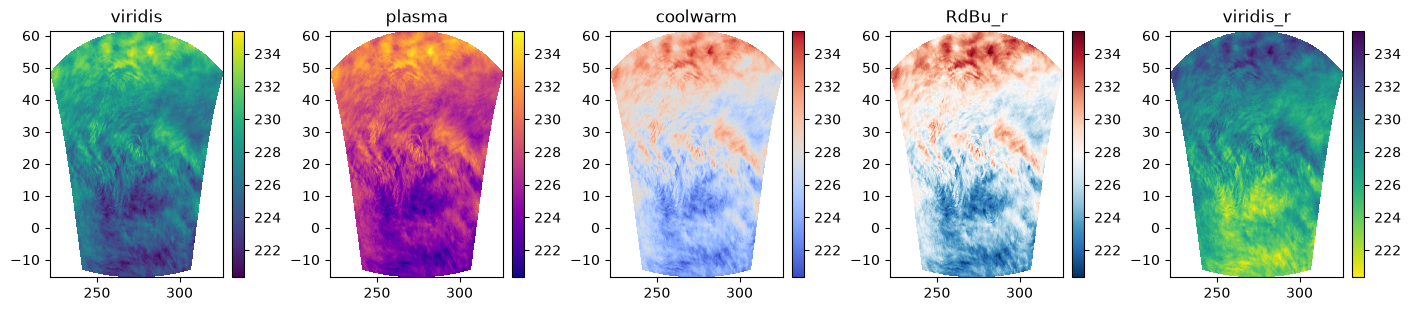

In [51]:
campo = ds["t"].sel(lev=10)
nombres = ["viridis", "plasma", "coolwarm", "RdBu_r", "viridis_r"]

fig, axs = plt.subplots(1, 5, figsize=(14, 3), layout="constrained")
for ax, nombre in zip(axs, nombres):
    mesh = ax.pcolormesh(ds.geolon, ds.geolat, campo, cmap=nombre)
    fig.colorbar(mesh, ax=ax)
    ax.set_title(nombre)
plt.show()

viridis y plasma van en un solo sentido, de un color a otro. Conviene para la temperatura, que va de frío a caliente. coolwarm y RdBu_r tienen un color en el centro y dos colores opuestos a los lados. Conviene para una anomalía, donde importa si el valor está por arriba o por abajo de cero. _r voltea el orden de los colores.

d) Poner lev=8 y lev=10 lado a lado con la misma escala (vmin, vmax) y una sola barra de color para ambos (fig.colorbar(mesh, ax=axs)).

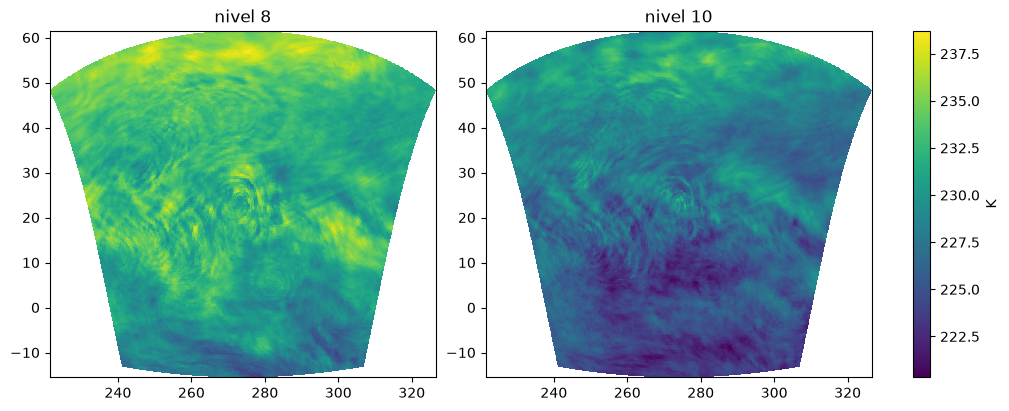

In [52]:
c8 = ds["t"].sel(lev=8)
c10 = ds["t"].sel(lev=10)
vmin = min(float(c8.min()), float(c10.min()))
vmax = max(float(c8.max()), float(c10.max()))

fig, axs = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axs[0].pcolormesh(ds.geolon, ds.geolat, c8, vmin=vmin, vmax=vmax, cmap="viridis")
mesh = axs[1].pcolormesh(ds.geolon, ds.geolat, c10, vmin=vmin, vmax=vmax, cmap="viridis")
axs[0].set_title("nivel 8")
axs[1].set_title("nivel 10")
fig.colorbar(mesh, ax=axs, label="K")
plt.show()

e) Calcular la anomalía: t menos su promedio en ese nivel. Graficarla con RdBu_r y norm=TwoSlopeNorm(vcenter=0). ¿Qué se ve ahora que antes no? Pista: TwoSlopeNorm se importa con from matplotlib.colors import TwoSlopeNorm; centra la escala de colores en vcenter, para que el cero quede en el color del centro del colormap.

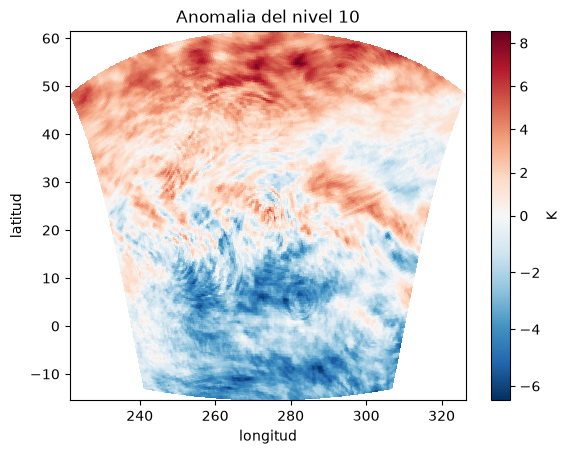

In [53]:
from matplotlib.colors import TwoSlopeNorm

campo = ds["t"].sel(lev=10)
anomalia = campo - campo.mean()

fig, ax = plt.subplots()
mesh = ax.pcolormesh(ds.geolon, ds.geolat, anomalia,
                     cmap="RdBu_r", norm=TwoSlopeNorm(vcenter=0))
fig.colorbar(mesh, ax=ax, label="K")
ax.set_xlabel("longitud")
ax.set_ylabel("latitud")
ax.set_title("Anomalia del nivel 10")
plt.show()

Ahora se ve dónde el aire está más caliente o más frío que el promedio de ese nivel. El mapa de temperatura absoluta muestra todo el nivel en un rango parecido; aquí el centro de la escala es el cero y resaltan las diferencias.

f) Hacer un corte vertical a lo largo de la columna lon=100: latitud en x, altura a media capa en y, con pcolormesh. Las dos coordenadas deben ser 2D de forma (lev, lat). Pista: la latitud se repite en cada nivel con np.broadcast_to. Para dejar fuera la capa del tope, se toma [1:] de z_km, t_corte y lat2d.

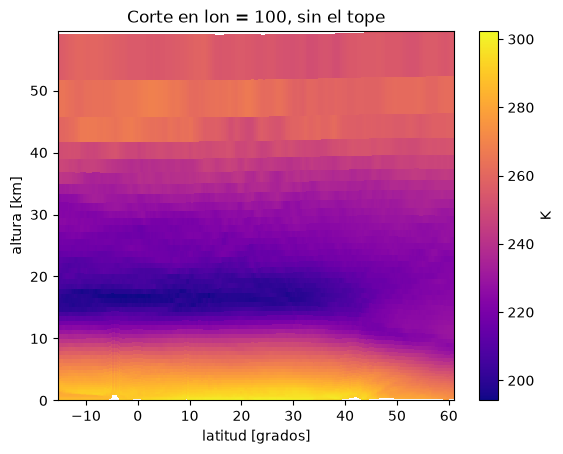

In [54]:
zh = ds["zh"].sel(lon=100).values          # (66, 240)
z_km = 0.5 * (zh[:-1] + zh[1:]) / 1000     # (65, 240), km
t_corte = ds["t"].sel(lon=100).values      # (65, 240)
lat2d = np.broadcast_to(lat.values, z_km.shape)

fig, ax = plt.subplots()
mesh = ax.pcolormesh(lat2d[1:], z_km[1:], t_corte[1:], cmap="plasma")
fig.colorbar(mesh, ax=ax, label="K")
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("altura [km]")
ax.set_title("Corte en lon = 100, sin el tope")
plt.show()

g) Poner el campo sobre un mapa con cartopy: subplot_kw={’projection’: ccrs.PlateCarree()}, transform=ccrs.PlateCarree() y ax.coastlines(). Pista: cartopy se importa con import cartopy.crs as ccrs, y subplot_kw va dentro de plt.subplots.

In [55]:
import sys
!{sys.executable} -m pip install cartopy

D:\juliette\ANACONDA\Lib\site-packages\cartopy\io\__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


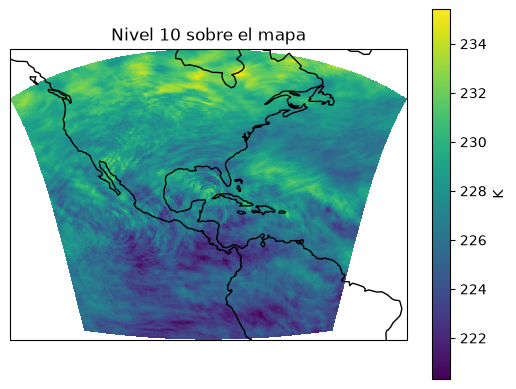

In [56]:
import cartopy.crs as ccrs

campo = ds["t"].sel(lev=10)
fig, ax = plt.subplots(subplot_kw={"projection": ccrs.PlateCarree()})
mesh = ax.pcolormesh(ds.geolon, ds.geolat, campo, transform=ccrs.PlateCarree())
ax.coastlines()
fig.colorbar(mesh, ax=ax, label="K")
ax.set_title("Nivel 10 sobre el mapa")
plt.show()

## 9. Anotaciones y detalles

a) Sobre t_10 contra lat, escribir un texto con ax.text en coordenadas de datos y otro fijo en la esquina superior izquierda con transform=ax.transAxes.

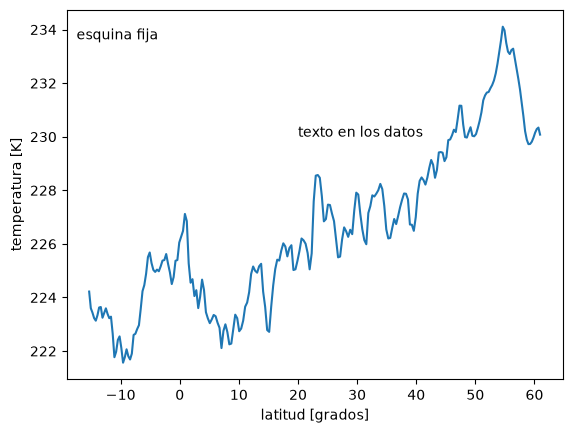

In [57]:
fig, ax = plt.subplots()
ax.plot(lat, t_10)
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("temperatura [K]")
ax.text(20, 230, "texto en los datos")
ax.text(0.02, 0.95, "esquina fija", transform=ax.transAxes, va="top")
plt.show()

b) Encontrar el máximo de t_10 (argmax) y señalarlo con ax.annotate, con flecha y el valor escrito. Pista: i = int(t_10.argmax()) da la posición del máximo, y el punto es (float(lat[i]), float(t_10[i])). Para la flecha: ax.annotate(’texto’, xy=punto, xytext=otro_punto, arrowprops=dict(arrowstyle=’->’)), donde xy es a dnde apunta la echa y xytext dónde va el texto.

C:\Users\juliette\AppData\Roaming\Python\Python314\site-packages\xarray\core\dataarray.py:6446: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)


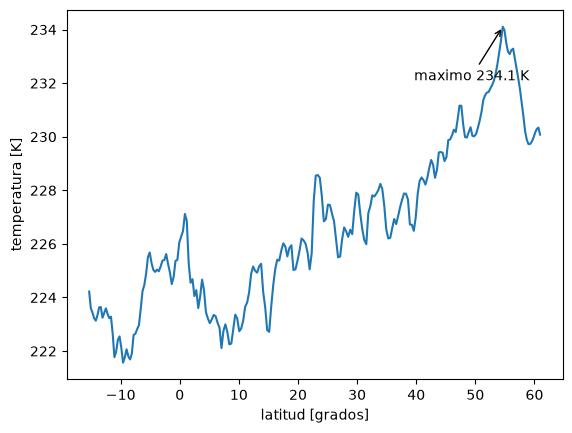

In [58]:
i = int(t_10.argmax())
punto = (float(lat[i]), float(t_10[i]))
texto = (punto[0] - 15, punto[1] - 2)

fig, ax = plt.subplots()
ax.plot(lat, t_10)
ax.annotate("maximo " + str(round(punto[1], 1)) + " K",
            xy=punto, xytext=texto,
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("temperatura [K]")
plt.show()

c) Cambiar las marcas del eje x a [-10, 0, 10, 20, 30, 40, 50] con etiquetas tipo ’10◦N’, y rotarlas 45◦ con ax.tick_params(axis=’x’, rotation=45). Pista: ax.set_xticks(valores, etiquetas), con las etiquetas como lista de textos.

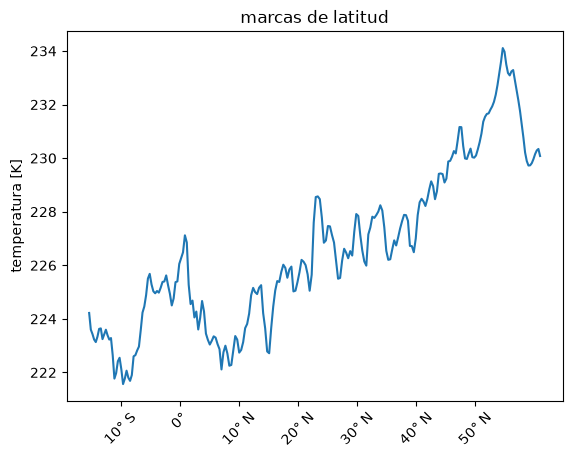

In [59]:
fig, ax = plt.subplots()
ax.plot(lat, t_10)
valores = [-10, 0, 10, 20, 30, 40, 50]
etiquetas = ["10° S", "0°", "10° N", "20° N", "30° N", "40° N", "50° N"]
ax.set_xticks(valores, etiquetas)
ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("temperatura [K]")
ax.set_title("marcas de latitud")
plt.show()

d) Sombrear la franja tropical (entre −23.5 y 23.5) con ax.axvspan.

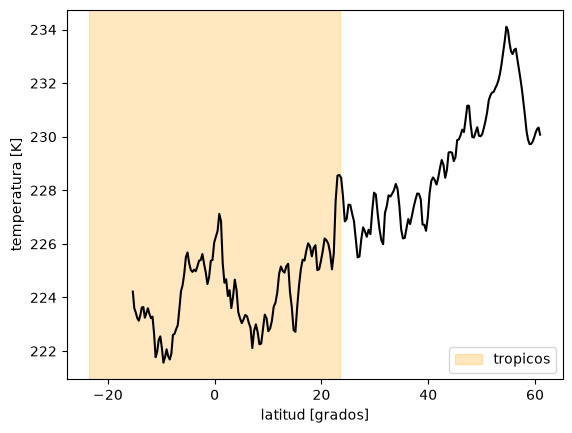

In [61]:
fig, ax = plt.subplots()
ax.plot(lat, t_10, color="black")
ax.axvspan(-23.5, 23.5, color="orange", alpha=0.25, label="tropicos")
ax.set_xlabel("latitud [grados]")
ax.set_ylabel("temperatura [K]")
ax.legend()
plt.show()

e) Usar LaTeX en las etiquetas: r’$T$ [K]’, r’$\Delta p$ [hPa]’.

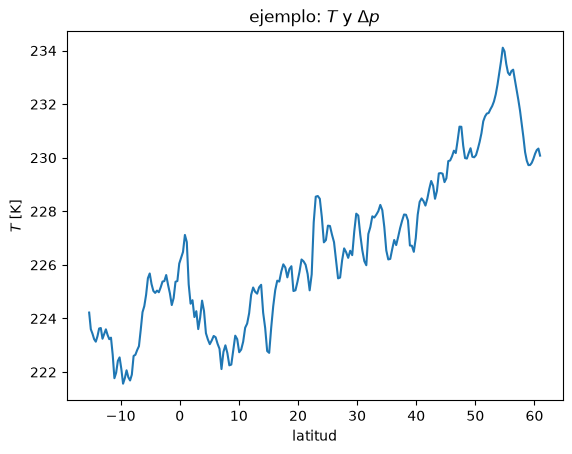

In [62]:
fig, ax = plt.subplots()
ax.plot(lat, t_10)
ax.set_xlabel(r"latitud")
ax.set_ylabel(r"$T$ [K]")
ax.set_title(r"ejemplo: $T$ y $\Delta p$")
plt.show()

## 10. Vectores: quiver y barbs

In [63]:
k = 40
u = ds["u_w"].sel(lev=k).values
v = ds["v_w"].sel(lev=k).values
u_c = 0.5 * (u[:, :-1] + u[:, 1:])
v_c = 0.5 * (v[:, :-1] + v[:, 1:])

lon = ds.geolon.values
gla = ds.geolat.values
print(u_c.shape, lon.shape)   # los dos (240, 240)

(240, 240) (240, 240)


a)  Dibujar echas con ax.quiver(geolon, geolat, u_c, v_c). Con 240×240 puntos no se distingue nada; submuestrear con [::10, ::10]. Pista: las coordenadas tambiØn se submuestrean:ds.geolon.values[::10, ::10].

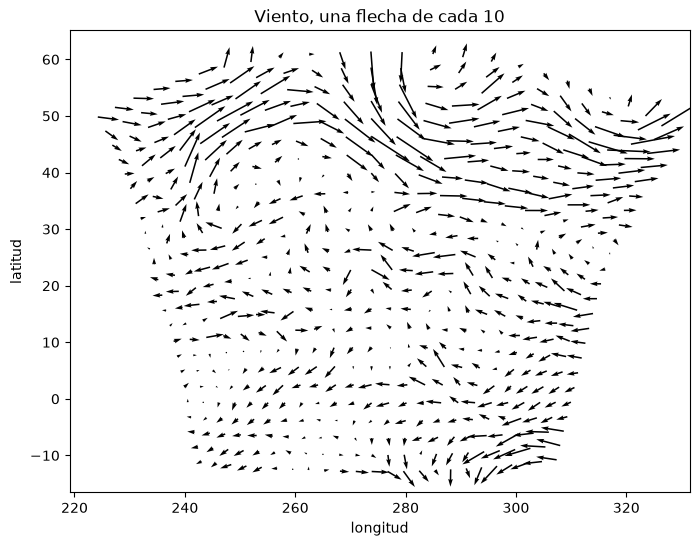

In [67]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.quiver(lon[::10, ::10], gla[::10, ::10], u_c[::10, ::10], v_c[::10, ::10])
ax.set_xlabel("longitud")
ax.set_ylabel("latitud")
ax.set_title("Viento, una flecha de cada 10")
plt.show()

b) Ajustar scale= y agregar una echa de referencia con ax.quiverkey. Pista: quiverkey recibe lo que regresa quiver: q = ax.quiver(...) y ax.quiverkey(q, X=0.9, Y=1.03, U=10, label=’10 m/s’), donde X y Y son la posici n en fracciones de los ejes y U el tamaæo de la flecha de referencia.

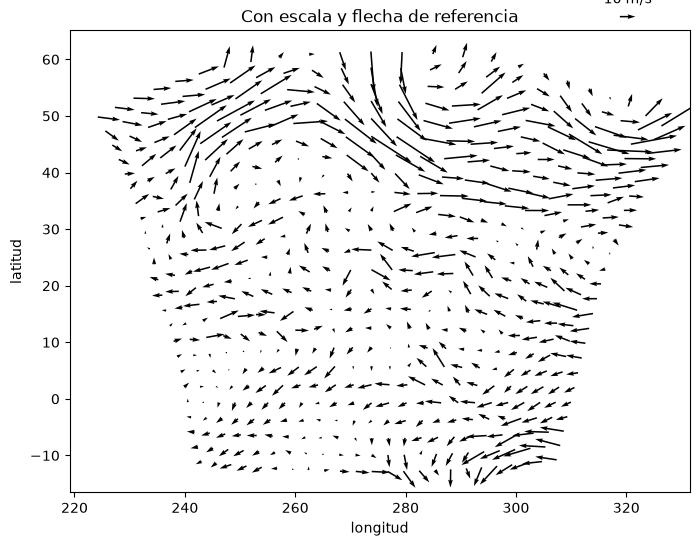

In [66]:
fig, ax = plt.subplots(figsize=(8, 6))
q = ax.quiver(lon[::10, ::10], gla[::10, ::10],
              u_c[::10, ::10], v_c[::10, ::10], scale=400)
ax.quiverkey(q, X=0.9, Y=1.03, U=10, label="10 m/s")
ax.set_xlabel("longitud")
ax.set_ylabel("latitud")
ax.set_title("Con escala y flecha de referencia")
plt.show()

c) Repetirlo con ax.barbs, con el viento en nudos (m/s × 1.944).

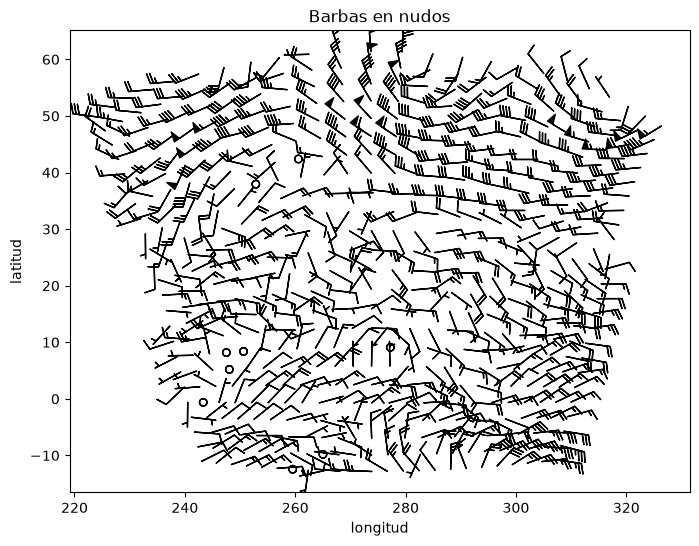

In [69]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.barbs(lon[::10, ::10], gla[::10, ::10],
         u_c[::10, ::10] * 1.944, v_c[::10, ::10] * 1.944,
         length=6)
ax.set_xlabel("longitud")
ax.set_ylabel("latitud")
ax.set_title("Barbas en nudos")
plt.show()

d) Colorear las echas por la magnitud del viento, pasando un quinto argumento a quiver. Pista: la magnitud es np.hypot(u_c, v_c), submuestreada igual que las flechas.

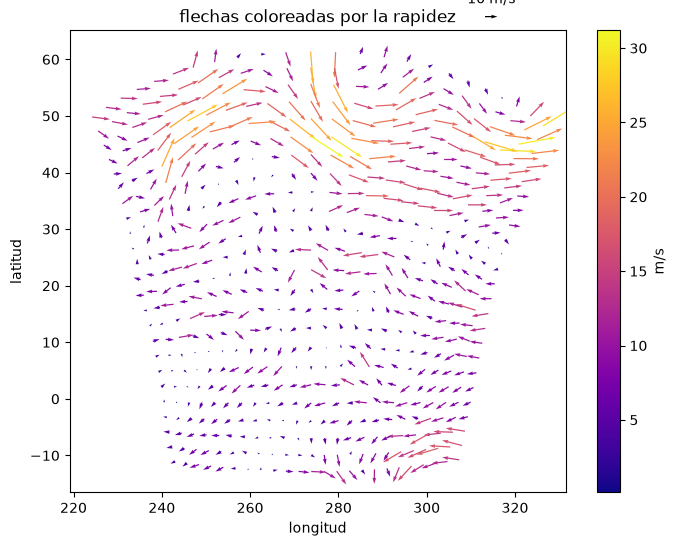

In [70]:
vel = np.hypot(u_c, v_c)

fig, ax = plt.subplots(figsize=(8, 6))
q = ax.quiver(lon[::10, ::10], gla[::10, ::10],
              u_c[::10, ::10], v_c[::10, ::10],
              vel[::10, ::10], scale=400, cmap="plasma")
fig.colorbar(q, ax=ax, label="m/s")
ax.quiverkey(q, X=0.85, Y=1.03, U=10, label="10 m/s")
ax.set_xlabel("longitud")
ax.set_ylabel("latitud")
ax.set_title("flechas coloreadas por la rapidez")
plt.show()